# Khai phá dữ liệu trên kho giá nông sản

Dữ liệu đã được luồng ETL (Airflow → MinIO → ClickHouse) làm sạch và nạp vào kho. Notebook này **chỉ đọc kho**
(view `ttns.v_price_monthly` = bảng sự kiện nối các bảng chiều), học máy, rồi ghi kết quả ngược lại kho để
Superset và ứng dụng dùng.

| Bài toán | Câu hỏi nghiệp vụ | Kỹ thuật |
|---|---|---|
| Dự báo giá tháng tới | Q2: mặt hàng nào sắp tăng giá? | Hồi quy: Linear Regression, Decision Tree, Random Forest + 2 mô hình cơ sở |
| Nhóm mặt hàng cùng nhịp giá | Q4: tháng nào rẻ, mặt hàng nào cùng mùa vụ? | Phân cụm K-Means |
| Chuỗi giá bất thường | cần kiểm tra lại với nguồn | DBSCAN |

Đơn vị phân tích là **chuỗi giá** = (mặt hàng, tỉnh, loại giá), mỗi tháng một giá trung vị. Chỉ dùng đơn vị VNĐ/kg.

In [1]:
import io
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.cluster import DBSCAN, KMeans
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score
from sklearn.model_selection import GridSearchCV, cross_validate
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

from publish_ml import CAT, CLUSTER_FEATS, KEY, NUM, SEED, add_features, cluster_features, name_cluster

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
FIG = Path("figures/khai_pha")
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 160, "savefig.bbox": "tight", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#9aa3af"


def show(fig, name):
    fig.savefig(FIG / f"{name}.png")
    plt.show()

## 1. Đọc dữ liệu từ kho
Nếu ClickHouse không chạy thì đọc bản chụp `data/ttns_v_price_monthly.csv` (xuất từ chính view này).

In [2]:
SQL = "SELECT * FROM ttns.v_price_monthly WHERE don_vi_tinh = 'VNĐ/kg' FORMAT CSVWithNames"
VUNG = {"Sơn La": "Trung du và miền núi phía Bắc", "TP. Hà Nội": "Đồng bằng sông Hồng",
        "Hưng Yên": "Đồng bằng sông Hồng", "Tây Ninh": "Đông Nam Bộ"}
try:
    r = requests.post(os.getenv("CLICKHOUSE_URL", "http://localhost:8123"), data=SQL.encode("utf-8"),
                      auth=("default", os.getenv("CLICKHOUSE_PASSWORD", "mypassword")), timeout=30)
    r.raise_for_status()
    raw, source = pd.read_csv(io.StringIO(r.text)), "ClickHouse"
except Exception as exc:
    raw = pd.read_csv("data/ttns_v_price_monthly.csv").query("don_vi_tinh == 'VNĐ/kg'")
    raw["vung"] = raw["tinh_moi"].map(VUNG).fillna("Đồng bằng sông Cửu Long")
    source = f"bản chụp CSV ({type(exc).__name__})"
raw["month"] = pd.to_datetime(raw["month"])
raw["sid"] = raw.groupby(KEY, sort=True).ngroup()
d = add_features(raw)
print(f"Nguồn: {source} — {len(d):,} bản ghi, {d['sid'].nunique()} chuỗi giá, "
      f"{d['month'].min():%m/%Y} → {d['month'].max():%m/%Y}")
d[KEY + ["cap_gia", "month", "median_price", "n_obs"]].head()

Nguồn: ClickHouse — 6,925 bản ghi, 429 chuỗi giá, 04/2021 → 12/2025


,nhom_san_pham,san_pham,mat_hang,tinh_cu,loai_gia,cap_gia,month,median_price,n_obs
0,Rau củ quả,Bí đao,Bí đao,Cần Thơ,Thu mua,Thu mua,2024-01-01,13000,4
1,Rau củ quả,Bí đao,Bí đao,Cần Thơ,Thu mua,Thu mua,2024-02-01,13000,5
2,Rau củ quả,Bí đao,Bí đao,Cần Thơ,Thu mua,Thu mua,2024-03-01,13500,4
3,Rau củ quả,Bí đao,Bí đao,Cần Thơ,Thu mua,Thu mua,2024-04-01,14000,4
4,Rau củ quả,Bí đao,Bí đao,Cần Thơ,Thu mua,Thu mua,2024-05-01,17000,5


## 2. Dự báo giá tháng tới
### 2.1 Đặc trưng và cách chia dữ liệu
Mỗi bản ghi chỉ dùng thông tin **trước** tháng cần dự báo:
- giá lần báo trước, giá tháng trước, trung bình 3 lần trước, giá cùng kỳ năm trước (đều lấy log);
- số tháng cách lần trước, biên độ max/min lần trước, số lần báo giá, thứ tự trong chuỗi, năm, tháng (sin/cos);
- biến phân loại: nhóm, sản phẩm, cấp giá, vùng (one-hot).

Chia **theo thời gian**: huấn luyện đến 12/2024, kiểm tra cả năm 2025. Cross-validation cũng theo khối tháng
(train luôn nằm trước validation). Chia ngẫu nhiên sẽ cho mô hình nhìn thấy tương lai.

In [3]:
TARGET = "median_price"
CUT = pd.Timestamp("2025-01-01")
train, test = d[d["month"] < CUT].reset_index(drop=True), d[d["month"] >= CUT].reset_index(drop=True)
X_train, y_train, X_test, y_test = train[NUM + CAT], train[TARGET], test[NUM + CAT], test[TARGET]


def time_folds(months, n_splits=4, min_train_months=12):
    uniq = np.sort(months.unique())
    for b in np.array_split(uniq[min_train_months:], n_splits):
        yield np.where(months < b[0])[0], np.where(months.isin(b))[0]


CV = list(time_folds(train["month"]))
print(f"Huấn luyện {len(train):,} bản ghi, kiểm tra {len(test):,} bản ghi; {len(CV)} fold CV theo thời gian")

Huấn luyện 5,005 bản ghi, kiểm tra 1,920 bản ghi; 4 fold CV theo thời gian


### 2.2 Mô hình
- **Cơ sở**: Dummy (luôn đoán trung vị) và *giữ nguyên giá* (tháng tới = lần báo giá trước).
- **Linear Regression, Decision Tree, Random Forest** học log(giá); tham số chọn bằng GridSearchCV theo thời gian.
- **Random Forest học độ thay đổi**: học log(giá) − log(giá lần trước). Khi không chắc, mô hình đoán gần 0, tức tự
  lùi về "giữ nguyên giá"; một mô hình dùng chung được cho mặt hàng 10.000đ và 200.000đ.

In [4]:
def make_pipeline(model, log_target=True):
    pre = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                          ("scale", StandardScaler())]), NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
    pipe = Pipeline([("pre", pre), ("model", model)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log, inverse_func=np.exp) if log_target else pipe


class DeltaRegressor(BaseEstimator, RegressorMixin):
    """Học log(giá) − log(giá lần trước); chuỗi chưa có lần trước dùng trung vị log giá của tập huấn luyện."""

    def __init__(self, model=None):
        self.model = model

    def _base(self, X):
        return X["log_gia_lan_truoc"].fillna(self.fill_).to_numpy()

    def fit(self, X, y):
        self.fill_ = float(np.median(np.log(y)))
        self.pipe_ = make_pipeline(clone(self.model), log_target=False).fit(X, np.log(np.asarray(y)) - self._base(X))
        return self

    def predict(self, X):
        return np.exp(self._base(X) + self.pipe_.predict(X))


def scores(y, p):
    return {"RMSE": np.sqrt(mean_squared_error(y, p)), "MAE": mean_absolute_error(y, p), "R²": r2_score(y, p)}


def cv_rmse(est):
    return -cross_validate(est, X_train, y_train, cv=CV, scoring="neg_root_mean_squared_error", n_jobs=-1)["test_score"].mean()


def grid(est, params):
    g = GridSearchCV(est, params, cv=CV, scoring="neg_root_mean_squared_error", n_jobs=-1).fit(X_train, y_train)
    return {k.split("__")[-1]: v for k, v in g.best_params_.items()}

Decision Tree: khảo sát `max_depth` để thấy underfitting (cây nông, cả hai sai số cao) và overfitting
(cây sâu, sai số huấn luyện giảm nhưng validation tăng).

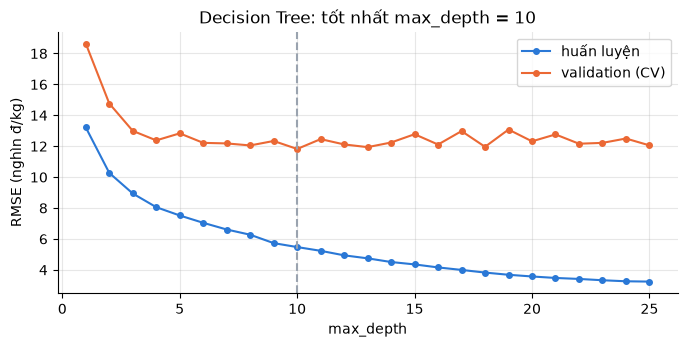

In [5]:
curve = pd.DataFrame([
    {"max_depth": k, **{s: -v.mean() for s, v in cross_validate(
        make_pipeline(DecisionTreeRegressor(max_depth=k, random_state=SEED)), X_train, y_train, cv=CV,
        scoring="neg_root_mean_squared_error", return_train_score=True, n_jobs=-1).items() if s.endswith("score")}}
    for k in range(1, 26)]).set_index("max_depth")
best_depth = int(curve["test_score"].idxmin())
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(curve.index, curve["train_score"] / 1000, color=BLUE, marker="o", ms=4, label="huấn luyện")
ax.plot(curve.index, curve["test_score"] / 1000, color=ORANGE, marker="o", ms=4, label="validation (CV)")
ax.axvline(best_depth, color=GRAY, ls="--")
ax.set(xlabel="max_depth", ylabel="RMSE (nghìn đ/kg)", title=f"Decision Tree: tốt nhất max_depth = {best_depth}")
ax.legend()
show(fig, "01_decision_tree_max_depth")

In [6]:
dt_params = grid(make_pipeline(DecisionTreeRegressor(random_state=SEED)),
                 {"regressor__model__max_depth": [best_depth + i for i in (-2, -1, 0, 1, 2)],
                  "regressor__model__min_samples_leaf": [1, 5, 10, 20]})
rf_params = grid(make_pipeline(RandomForestRegressor(random_state=SEED, n_jobs=1)),
                 {"regressor__model__n_estimators": [300], "regressor__model__max_depth": [10, 20, None],
                  "regressor__model__min_samples_leaf": [1, 3, 8], "regressor__model__max_features": ["sqrt", 0.5, 1.0]})
delta_params = grid(DeltaRegressor(RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=1)),
                    {"model__min_samples_leaf": [1, 5, 10, 20, 40], "model__max_features": [0.5, 1.0]})
print("Decision Tree:", dt_params, "\nRandom Forest:", rf_params, "\nRF học độ thay đổi:", delta_params)

Decision Tree: {'max_depth': 10, 'min_samples_leaf': 1} 
Random Forest: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 1, 'n_estimators': 300} 
RF học độ thay đổi: {'max_features': 0.5, 'min_samples_leaf': 1}


### 2.3 Đánh giá trên năm 2025
Mô hình được chọn theo RMSE của cross-validation; năm 2025 chỉ dùng để báo cáo kết quả cuối.

In [7]:
models = {
    "Cơ sở: Dummy (trung vị)": make_pipeline(DummyRegressor(strategy="median")),
    "Linear Regression": make_pipeline(LinearRegression()),
    f"Decision Tree (max_depth {dt_params['max_depth']})": make_pipeline(DecisionTreeRegressor(random_state=SEED, **dt_params)),
    "Random Forest": make_pipeline(RandomForestRegressor(random_state=SEED, n_jobs=-1, **rf_params)),
    "RF học độ thay đổi": DeltaRegressor(RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1, **delta_params)),
}
rows = {}
for name, est in models.items():
    rows[name] = {"RMSE CV": cv_rmse(est), **scores(y_test, est.fit(X_train, y_train).predict(X_test))}
naive_cv = np.mean([np.sqrt(mean_squared_error(
    train[TARGET].iloc[va], np.exp(train["log_gia_lan_truoc"].iloc[va]).fillna(np.exp(train["log_gia"].iloc[tr].median()))))
    for tr, va in CV])
naive = np.exp(test["log_gia_lan_truoc"]).fillna(np.exp(train["log_gia"].median()))
rows["Cơ sở: giữ nguyên giá"] = {"RMSE CV": naive_cv, **scores(y_test, naive)}
result = pd.DataFrame(rows).T.loc[["Cơ sở: Dummy (trung vị)", "Cơ sở: giữ nguyên giá"] + list(models)[1:]]
result.style.format({"RMSE CV": "{:,.0f}", "RMSE": "{:,.0f}", "MAE": "{:,.0f}", "R²": "{:.3f}"})

,RMSE CV,RMSE,MAE,R²
Cơ sở: Dummy (trung vị),"22,071","22,674","13,531",-0.068
Cơ sở: giữ nguyên giá,"10,911","8,202","3,439",0.860
Linear Regression,"12,405","8,143","4,163",0.862
Decision Tree (max_depth 10),"11,821","9,940","4,485",0.795
Random Forest,"11,012","8,221","3,805",0.860
RF học độ thay đổi,"10,313","7,700","3,585",0.877


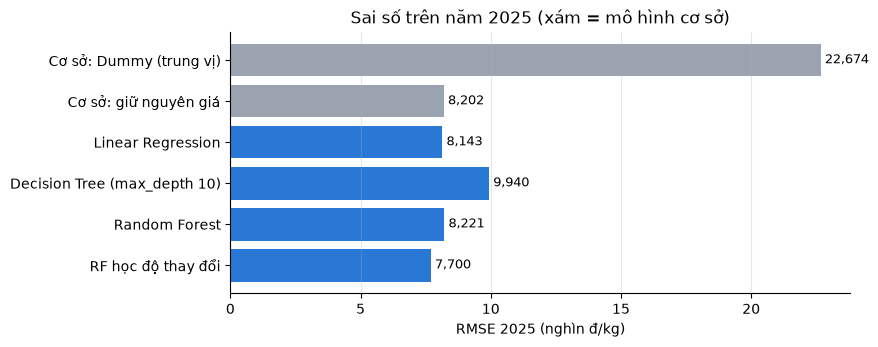

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.4))
vals = result["RMSE"].iloc[::-1]
ax.barh(vals.index, vals / 1000, color=[GRAY if n.startswith("Cơ sở") else BLUE for n in vals.index])
for i, v in enumerate(vals):
    ax.text(v / 1000, i, f" {v:,.0f}", va="center", fontsize=9)
ax.set(xlabel="RMSE 2025 (nghìn đ/kg)", title="Sai số trên năm 2025 (xám = mô hình cơ sở)")
ax.grid(axis="y", visible=False)
show(fig, "02_so_sanh_mo_hinh")

**Nhận xét.** Giá có quán tính lớn: chỉ "giữ nguyên giá" đã đạt R² ≈ 0,86, và các mô hình học mức giá chỉ ngang
mốc này. Học **độ thay đổi** giúp Random Forest giảm RMSE khoảng 6,5% so với giữ nguyên giá. MAE vẫn thua nhẹ:
mô hình giảm được các lần đoán trật lớn (khi giá biến động theo mùa) chứ không cải thiện các tháng giá đứng yên.

## 3. Phân cụm chuỗi giá theo hành vi
### 3.1 Đặc trưng
Mỗi chuỗi có ít nhất 24 tháng được mô tả bằng 6 đặc trưng **hành vi**, không dùng mức giá (nếu dùng, K-Means chỉ
tách "hàng đắt" với "hàng rẻ"): biên độ mùa vụ, tháng đỉnh (sin/cos), độ biến động, xu hướng/năm, tỷ lệ tháng
đứng giá. Chuẩn hoá trước khi phân cụm vì K-Means dùng khoảng cách Euclid.

In [9]:
F = cluster_features(d).set_index("sid")
X = StandardScaler().fit_transform(F[CLUSTER_FEATS])
print(f"{len(F)} chuỗi đủ điều kiện")
F[CLUSTER_FEATS].describe().T[["mean", "std", "min", "max"]]

122 chuỗi đủ điều kiện


,mean,std,min,max
bien_do_mua_vu,0.441,0.259,0.032,1.216
thang_dinh_sin,0.059,0.726,-1.000,1.000
thang_dinh_cos,0.068,0.687,-1.000,1.000
do_bien_dong,0.192,0.100,0.024,0.555
xu_huong_nam,0.014,0.138,-0.389,0.576
ty_le_dung_gia,0.369,0.197,0.000,0.938


### 3.2 K-Means: chọn K bằng Elbow và Silhouette

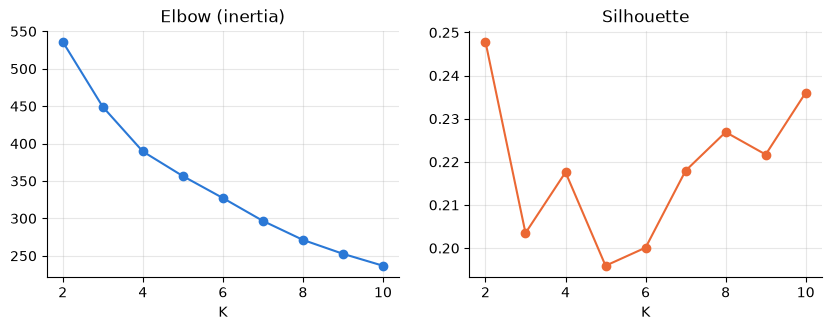

In [10]:
ks = range(2, 11)
fits = [KMeans(n_clusters=k, n_init=30, random_state=SEED).fit(X) for k in ks]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(list(ks), [m.inertia_ for m in fits], color=BLUE, marker="o")
axes[0].set(title="Elbow (inertia)", xlabel="K")
axes[1].plot(list(ks), [silhouette_score(X, m.labels_) for m in fits], color=ORANGE, marker="o")
axes[1].set(title="Silhouette", xlabel="K")
show(fig, "03_chon_k")

In [11]:
K = 4
F["cluster_id"] = KMeans(n_clusters=K, n_init=30, random_state=SEED).fit_predict(X)
centers = F.groupby("cluster_id").agg(bien_do_mua_vu=("bien_do_mua_vu", "mean"), do_bien_dong=("do_bien_dong", "mean"),
                                      xu_huong_nam=("xu_huong_nam", "mean"),
                                      thang_dinh=("thang_dinh", lambda s: s.mode().iloc[0]))
names = {i: name_cluster(c, F) for i, c in centers.iterrows()}
F["ten_cum"] = F["cluster_id"].map(names)
print(f"K = {K}, silhouette = {silhouette_score(X, F['cluster_id']):.2f}")
for i, n in names.items():
    sub = F[F["cluster_id"] == i]
    print(f"Cụm {i} · {n} · {len(sub)} chuỗi: {', '.join(sub['san_pham'].value_counts().index[:6])}")

K = 4, silhouette = 0.22
Cụm 0 · Ổn định, ít mùa vụ · 33 chuỗi: Bưởi, Nhãn, Khoai tây, Cà rốt, Ổi, Chuối
Cụm 1 · Biến động mạnh, mùa vụ sâu, giá đi xuống · 17 chuỗi: Xoài, Thanh long, Cam, Nhãn, Sầu riêng, Rau ngót
Cụm 2 · Mùa vụ vừa, đỉnh T4 · 34 chuỗi: Cam, Chanh, Xoài, Quả bí, Mướp, Quýt
Cụm 3 · Mùa vụ vừa, đỉnh T12, giá tăng dần · 38 chuỗi: Dưa hấu, Xoài, Cà chua, Khổ qua, Bắp cải, Bầu


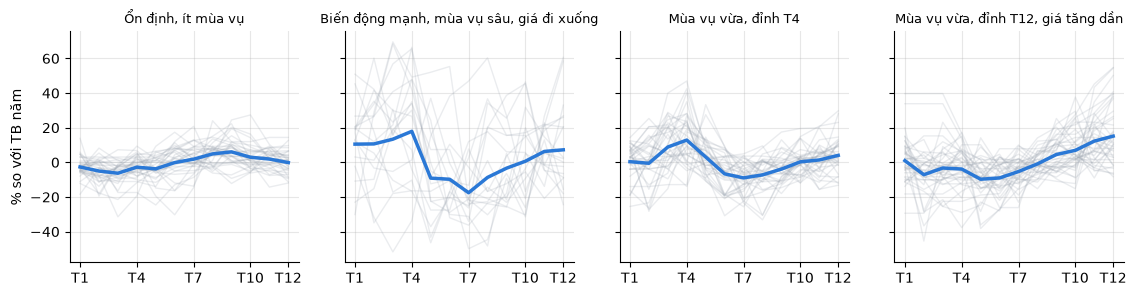

In [12]:
d["dev"] = d["log_gia"] - d.groupby(["sid", d["month"].dt.year])["log_gia"].transform("mean")
prof = d[d["sid"].isin(F.index)].groupby(["sid", d["month"].dt.month])["dev"].mean().unstack()
fig, axes = plt.subplots(1, K, figsize=(3.4 * K, 3), sharey=True)
for ax, i in zip(axes, range(K)):
    p = prof.loc[F.index[F["cluster_id"] == i]]
    ax.plot(range(1, 13), np.expm1(p.T.values) * 100, color=GRAY, alpha=0.2, lw=1)
    ax.plot(range(1, 13), np.expm1(p.mean().values) * 100, color=BLUE, lw=2.5)
    ax.set_title(names[i], fontsize=9.5)
    ax.set_xticks([1, 4, 7, 10, 12], ["T1", "T4", "T7", "T10", "T12"])
axes[0].set_ylabel("% so với TB năm")
show(fig, "04_hinh_dang_cum")

Silhouette chỉ khoảng 0,22: cụm có chồng lấn, nên đọc như **xu hướng** chứ không phải nhóm tách bạch. Các cụm vẫn có
ý nghĩa nghiệp vụ rõ, ví dụ rau vụ đông đỉnh giá tháng 12, cây có múi đỉnh tháng 4.

### 3.3 DBSCAN: tìm chuỗi dị biệt
`min_samples` = số chiều + 1 = 7. `eps` lấy tại điểm gãy của đồ thị khoảng cách tới láng giềng thứ 7. Điểm không
thuộc vùng dày đặc nào được gán nhãn −1 (nhiễu) = chuỗi có hành vi dị biệt.

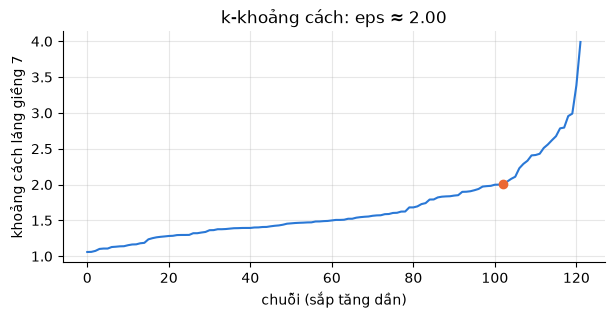

6 chuỗi dị biệt / 122


,mat_hang,tinh_cu,cap_gia,bien_do_mua_vu,do_bien_dong,xu_huong_nam
sid,,,,,,
409,Xoài Đài Loan,Đồng Tháp,Thu mua,1.216,0.555,-0.016
212,Cóc Thái,Đồng Tháp,Thu mua,1.120,0.513,-0.169
340,Sầu Riêng Ri 6 (loại xô),Cần Thơ,Thu mua,0.780,0.338,-0.368
319,Nhãn tiêu da bò,Đồng Tháp,Thu mua,0.672,0.275,-0.389
401,Xoài cát Hòa Lộc,Đồng Tháp,Thu mua,0.738,0.275,-0.027
193,Chanh leo tím,Sơn La,Bán lẻ,0.517,0.118,0.576


In [13]:
MIN_SAMPLES = len(CLUSTER_FEATS) + 1
kd = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X).kneighbors(X)[0][:, -1])
xs = np.arange(len(kd))
knee = int(np.argmax(np.abs((kd[-1] - kd[0]) * xs - (len(kd) - 1) * (kd - kd[0]))))
EPS = float(kd[knee])
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(xs, kd, color=BLUE)
ax.scatter([knee], [EPS], color=ORANGE, zorder=3)
ax.set(title=f"k-khoảng cách: eps ≈ {EPS:.2f}", xlabel="chuỗi (sắp tăng dần)", ylabel=f"khoảng cách láng giềng {MIN_SAMPLES}")
show(fig, "05_k_distance")

F["dbscan_label"] = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(X)
outliers = F[F["dbscan_label"] == -1]
print(f"{len(outliers)} chuỗi dị biệt / {len(F)}")
outliers[["mat_hang", "tinh_cu", "cap_gia", "bien_do_mua_vu", "do_bien_dong", "xu_huong_nam"]].sort_values(
    "do_bien_dong", ascending=False)

**K-Means hay DBSCAN?** K-Means ép mọi chuỗi vào một cụm nên hợp để **phân khúc** mặt hàng theo nhịp giá (lập kế
hoạch thu mua theo mùa). DBSCAN dựa vào mật độ và để riêng điểm lạc loài nên hợp để **phát hiện bất thường**.

## 4. Ghi kết quả vào kho
`publish_ml.py` huấn luyện lại mô hình đã chọn trên toàn bộ dữ liệu, dự báo tháng kế tiếp kèm khoảng 80% và ghi
`ttns.ml_forecast`, `ttns.ml_cluster`, `ttns.ml_metrics`. Dashboard "Khai phá" trên Superset đọc các bảng này.

In [14]:
if source == "ClickHouse":
    import publish_ml
    publish_ml.main()

Dữ liệu: 6,925 dòng, 429 chuỗi, đến 12/2025


                model      rmse       mae    r2  mape
   RF học độ thay đổi 7,700.484 3,585.328 0.877 0.157
Cơ sở: giữ nguyên giá 8,202.409 3,439.089 0.860 0.148


K-Means K=4; DBSCAN eps=2.00: 6 chuỗi dị biệt / 122


ttns.ml_forecast: 203 dòng


ttns.ml_cluster: 122 dòng
ttns.ml_metrics: 2 dòng


## 5. Kết luận
- **Dự báo giá:** Random Forest học độ thay đổi tốt nhất (RMSE 2025 thấp hơn "giữ nguyên giá" khoảng 6,5%). Giá
  nông sản có quán tính lớn nên mốc "giữ nguyên giá" rất khó vượt.
- **Phân cụm:** 4 nhịp giá (ổn định; biến động mạnh; đỉnh tháng 4; đỉnh tháng 12). Cụm yếu (silhouette ≈ 0,22).
- **Dị biệt:** DBSCAN tách 6 chuỗi, phần lớn là giá thu mua trái cây biến động rất mạnh.
- **Hạn chế:** chuỗi ngắn (tối đa 57 tháng) và thưa; giá bán lẻ và thu mua đo ở hai miền khác nhau. Hướng tiếp:
  thêm thời tiết, lịch Tết; dự báo nhiều tháng; đưa huấn luyện thành DAG Airflow.